# TD-JEPA: zero-shot goals and rewards from reward-free data

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/action/tdjepa.ipynb)

[TD-JEPA](https://arxiv.org/abs/2510.00739) (code not released) brings latent prediction to zero-shot RL. A state encoder, a task encoder and a family of policies, one per task embedding $z$, are learned from reward-free transitions. The predictor is trained by temporal differences to forecast the discounted future *task embeddings* under policy $\pi_z$, which makes it a value function for every reward that is linear in the task embedding. At test time nothing is trained: a goal image, or frames labeled with a reward, give $z$, and $\pi_z$ acts.

Here it learns Two-Rooms from the pixels of random-action episodes, then reaches goal images across the wall and in the same room, and finally maximizes rewards it never saw in training.

In [1]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]"

In [2]:
import torch
from torch.utils.data import DataLoader

from torch_world import evaluation, metrics, plots
from torch_world.datasets import TrajectoryDataset
from torch_world.envs import TwoRooms
from torch_world.models import TDJEPA
from torch_world.models.jepa import drq_encoder
from torch_world.utils import fit

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

## Data and model
The point moves at random, keeping its previous action with probability 0.8: no rewards and no goals. TD-JEPA trains on single transitions $(s, a, s')$, windows of two frames. The model follows the paper's DMC-from-pixels setting: DrQ-v2 convolutions under a linear state encoder $\phi$ (256-d) and a two-layer task encoder $\psi$ (50-d), twin predictors 1024 wide, a Gaussian actor with fixed std 0.2.

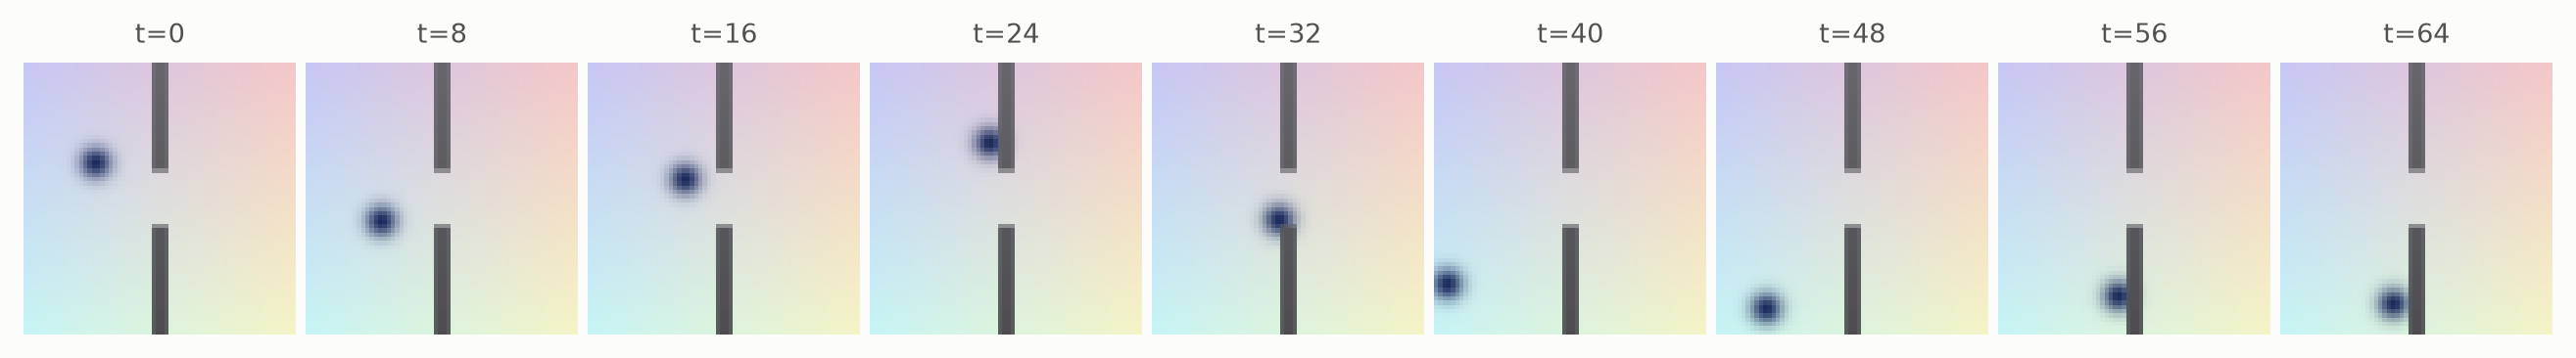

In [3]:
data = TwoRooms(batch_size=1024, device=device).collect(65, generator=torch.Generator().manual_seed(0))
loader = DataLoader(TrajectoryDataset(data, window=2), batch_size=256, shuffle=True, drop_last=True)
plots.images(data["pixels"][0, ::8].cpu(), [f"t={t}" for t in range(0, 65, 8)], ncols=9)

In [4]:
model = TDJEPA(drq_encoder(256), drq_encoder(50, hidden_layers=2), action_dim=2, discount=0.98).to(device)
print(f"{sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6:.1f}M trained parameters, {len(loader)} steps per epoch")

18.3M trained parameters, 256 steps per epoch


## Train
Algorithm 1 in one backward pass per batch: the two TD latent-prediction losses against EMA targets, the orthonormality regularizer on both encoders, and the actor loss, which reaches only the actor. Adam (AdamW without weight decay) at the paper's learning rate, and the targets move after every step. The TD losses rise at first and then plateau: the targets grow as the encoders spread out and the bootstrapped sums lengthen, so they do not go to zero.

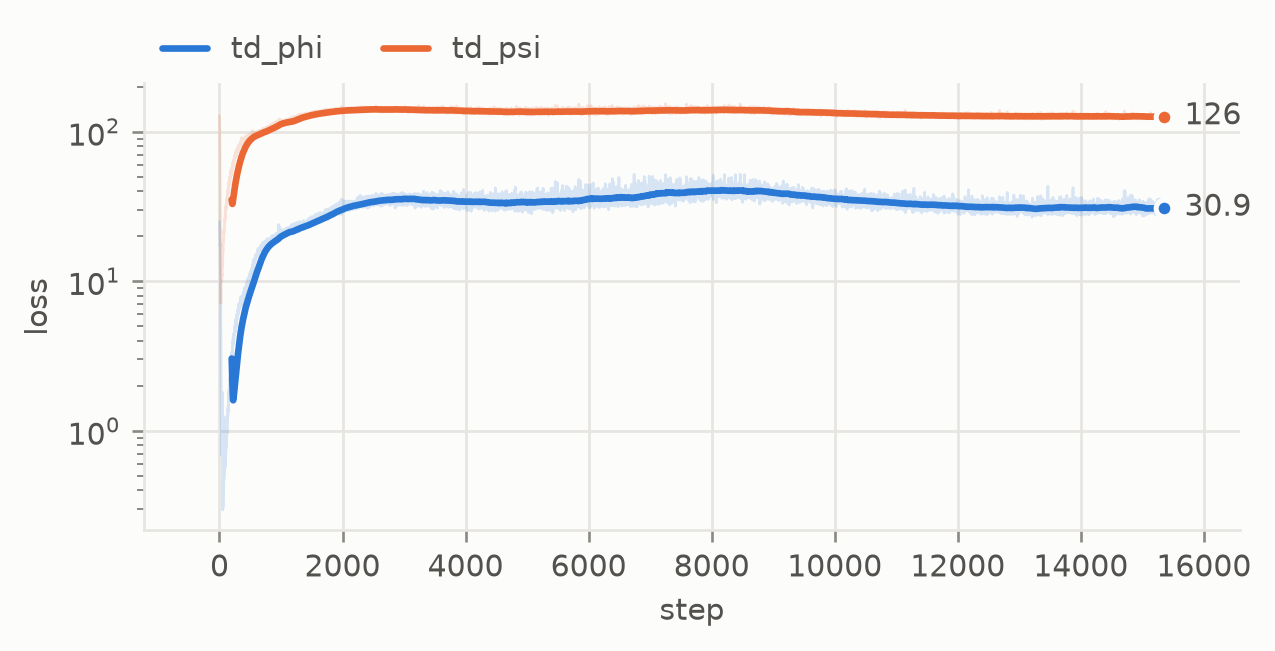

In [5]:
log = fit(model, loader, epochs=60, lr=1e-4, weight_decay=0, step=lambda: model.update_target(0.995))
plots.curves({k: log[k] for k in ("td_phi", "td_psi")}, smooth=200)

After the first few hundred steps, the orthonormality term settles (the encoders spread their embeddings) while the actor loss keeps falling: it is minus the predicted value $T_\phi(\phi(s), \hat a, z)^\top z$, which grows as the predictors learn longer-horizon successor features and the policies improve.

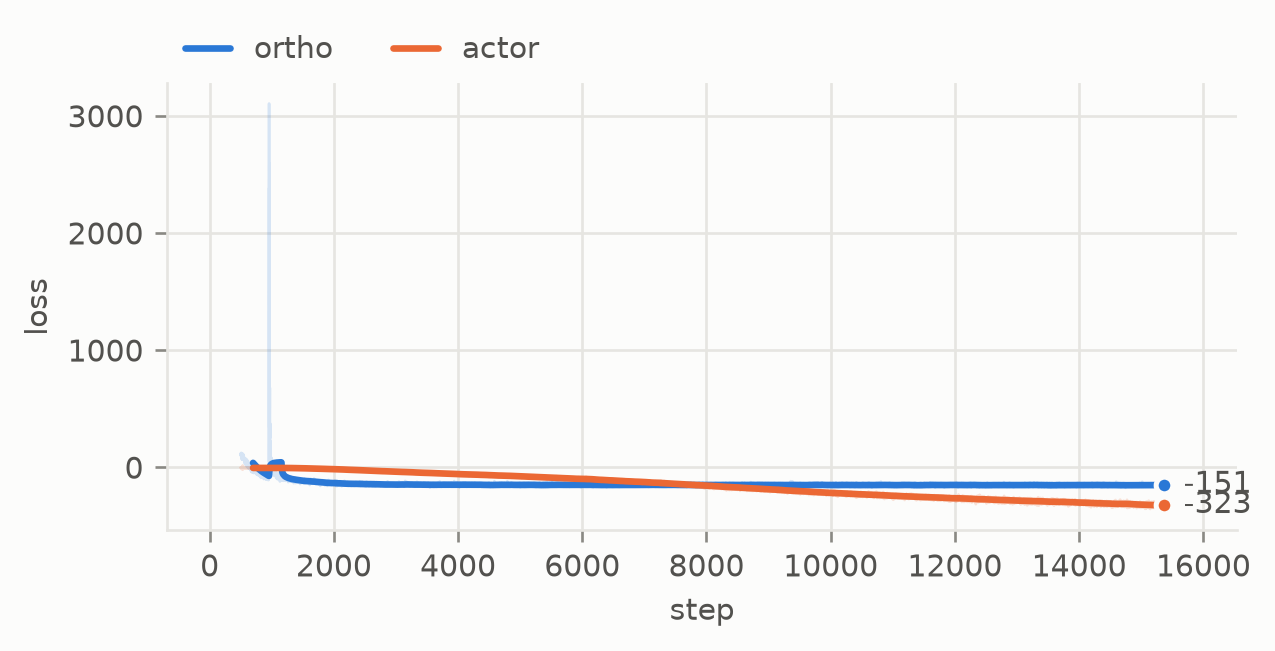

In [6]:
plots.curves({k: (range(500, len(log[k])), log[k][500:]) for k in ("ortho", "actor")}, smooth=200, logy=False)

## Zero-shot goal reaching
Each goal image gives a task embedding $z_g = \psi(g)$, projected onto the sphere the policies were trained on; the policy $\pi_{z_g}$ then acts on every new frame, with no planning and no further training. Two goal sets come from the same model: goals in the other room, where the way runs through the door, and goals in the same room. Success means coming within 0.1 of the goal within 60 steps. A controller that knows the true positions and heads straight for the goal shows what the wall costs; random actions are the floor.

other room
                               success  reached   steps  final distance  progress     SPL  smoothness  ms / step
TD-JEPA (zero-shot)    98% [92%, 100%]      98%    6.24          0.0681     0.889   0.174        1.69      0.312
greedy (true state)     31% [21%, 43%]      31%    4.85           0.283     0.521     0.3      0.0133     0.0119
random actions            3% [1%, 11%]       3%    36.5           0.643  -0.00931 0.00296        1.04     0.0134



same room
                               success  reached   steps  final distance  progress     SPL  smoothness  ms / step
TD-JEPA (zero-shot)   100% [94%, 100%]     100%    2.62           0.071     0.776   0.176        1.68      0.307
greedy (true state)    98% [92%, 100%]      98%    2.49        6.66e-08         1   0.955       0.025     0.0116
random actions          50% [38%, 62%]      52%    19.3           0.342    -0.119  0.0312        1.04     0.0137



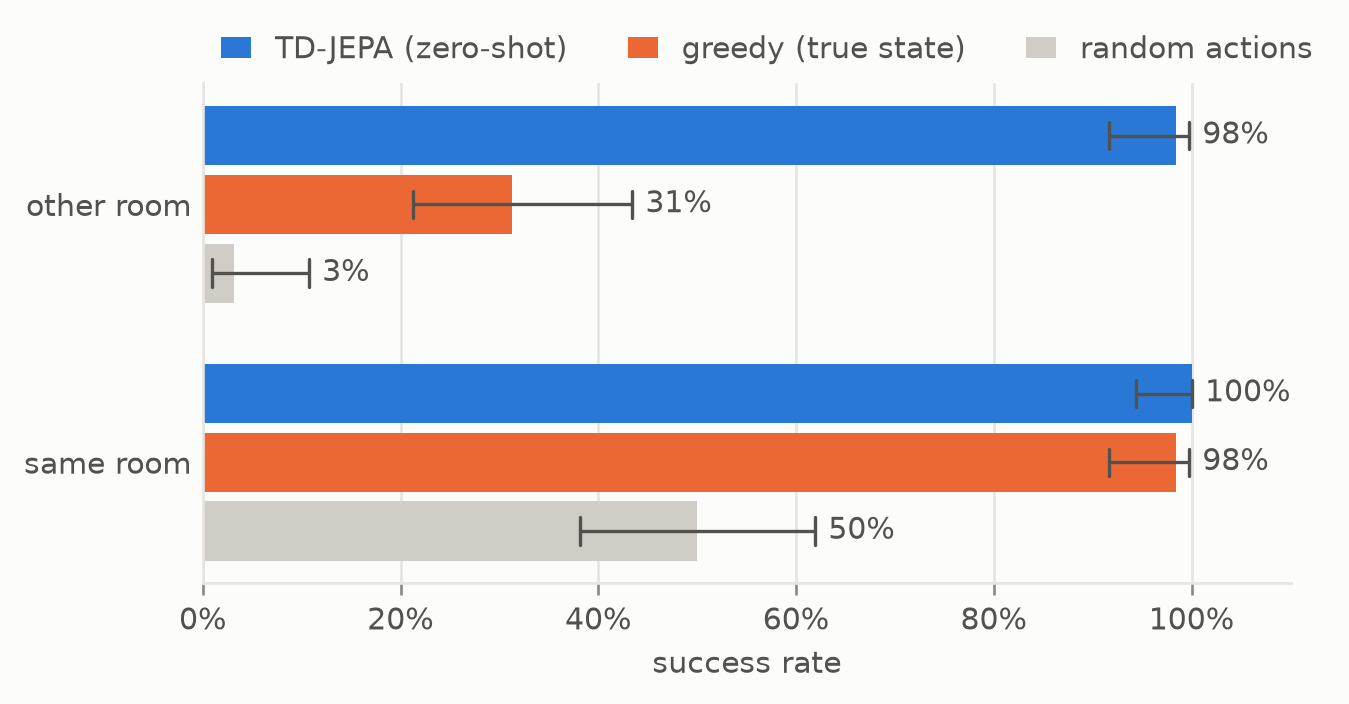

In [7]:
env = TwoRooms(batch_size=64, device=device)
results, goals = {}, {}
for name, same_room in {"other room": False, "same room": True}.items():
    start, goal = env.tasks(generator=torch.Generator().manual_seed(1), same_room=same_room)
    goals[name] = goal
    policies = {
        "TD-JEPA (zero-shot)": model.controller(model.goal_task(env.render(goal))),
        "greedy (true state)": lambda obs, goal=goal: ((goal - env.state) / env.max_step).clamp(-1, 1),
        "random actions": evaluation.random_policy(env),
    }
    results[name] = evaluation.goal_reaching(env, policies, start, goal, steps=60, success="reached")
    print(name, results[name], sep="\n", end="\n\n")
plots.bars({name: r.intervals() for name, r in results.items()}, xlabel="success rate", baseline="random actions")

Paths toward goals in the other room, over the goal images; the darker, the later:

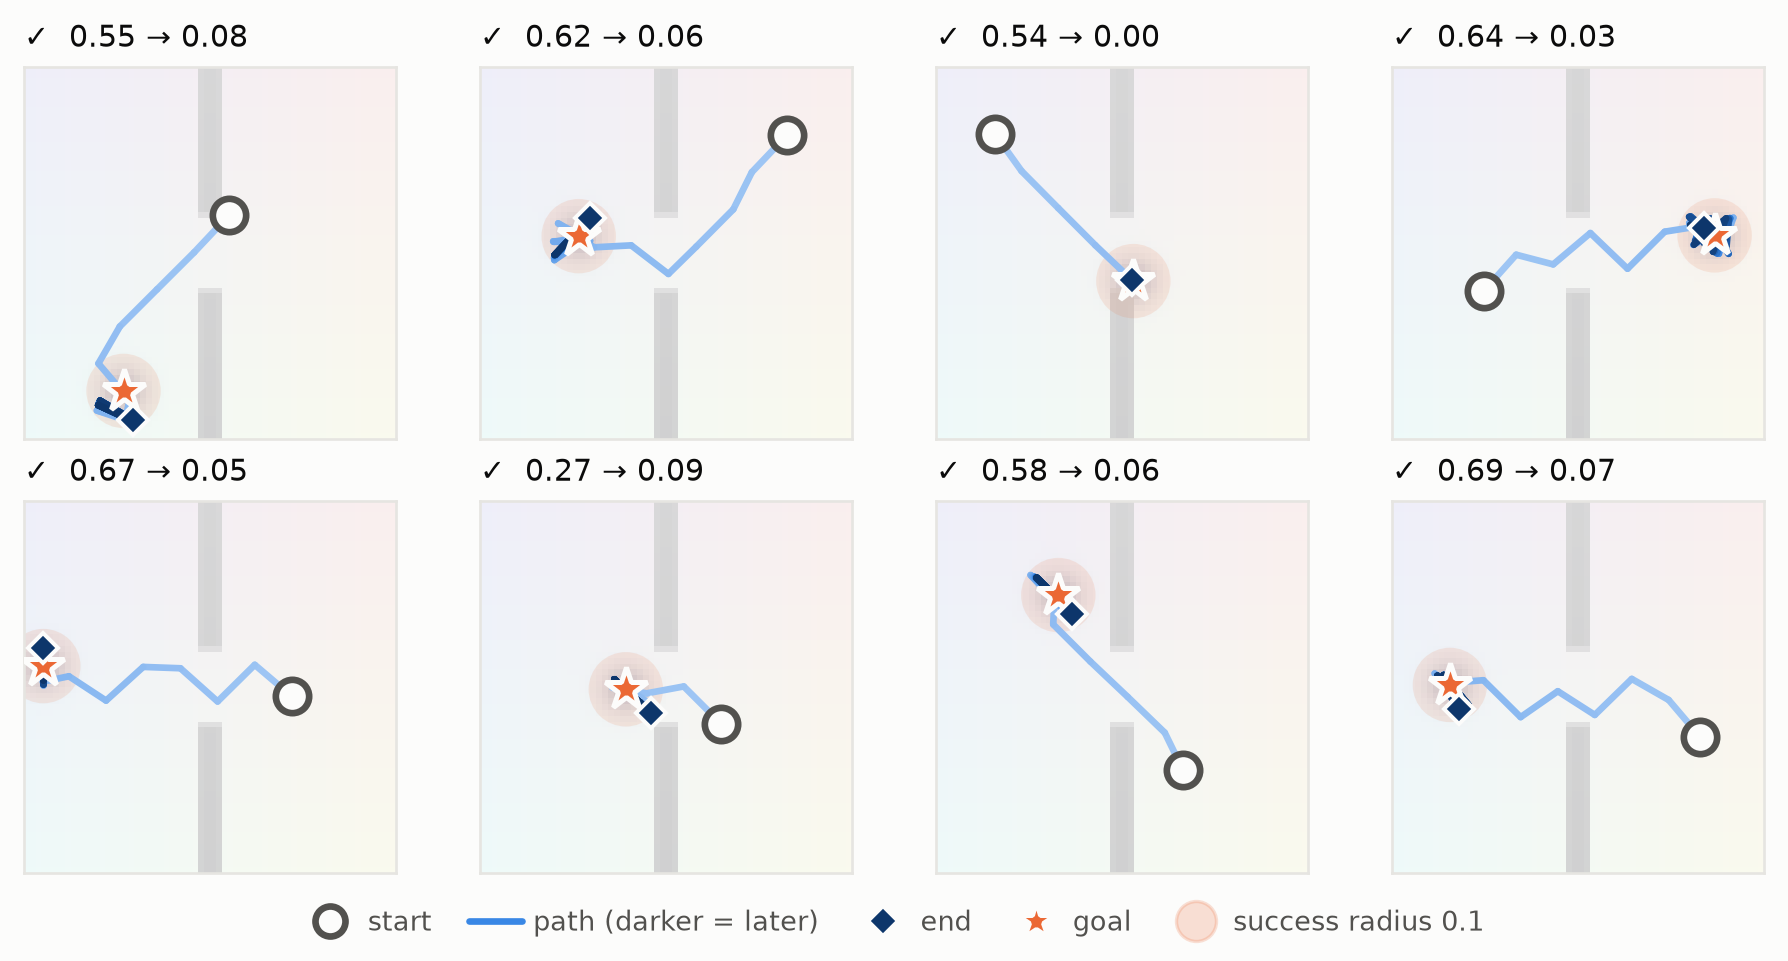

In [8]:
run = results["other room"]
won, goal = run.success["TD-JEPA (zero-shot)"][:8], goals["other room"]
plots.trajectories(run.paths["TD-JEPA (zero-shot)"][:8].cpu(), goal[:8].cpu(), radius=env.radius, background=env.render(goal[:8]).cpu(), success=won.cpu())

## Zero-shot rewards
The same policies optimize any reward in the span of $\psi$. Label 2,048 dataset frames with a reward the model never saw, regress it onto $\psi$ to get $z_r = \mathbb{E}[\psi\psi^\top]^{-1}\mathbb{E}[\psi\, r]$, and run $\pi_{z_r}$: one linear solve, no gradient step. Three rewards: be in the left strip, be in the bottom-right corner, stand in the doorway. An episode succeeds when it ends in the rewarded region after 40 steps, from 64 random starts.

left strip          TD-JEPA (zero-shot): 89% [79%, 95%]  random actions: 9% [4%, 19%]
bottom-right corner TD-JEPA (zero-shot): 94% [85%, 98%]  random actions: 8% [3%, 17%]


doorway             TD-JEPA (zero-shot): 100% [94%, 100%]  random actions: 0% [0%, 6%]


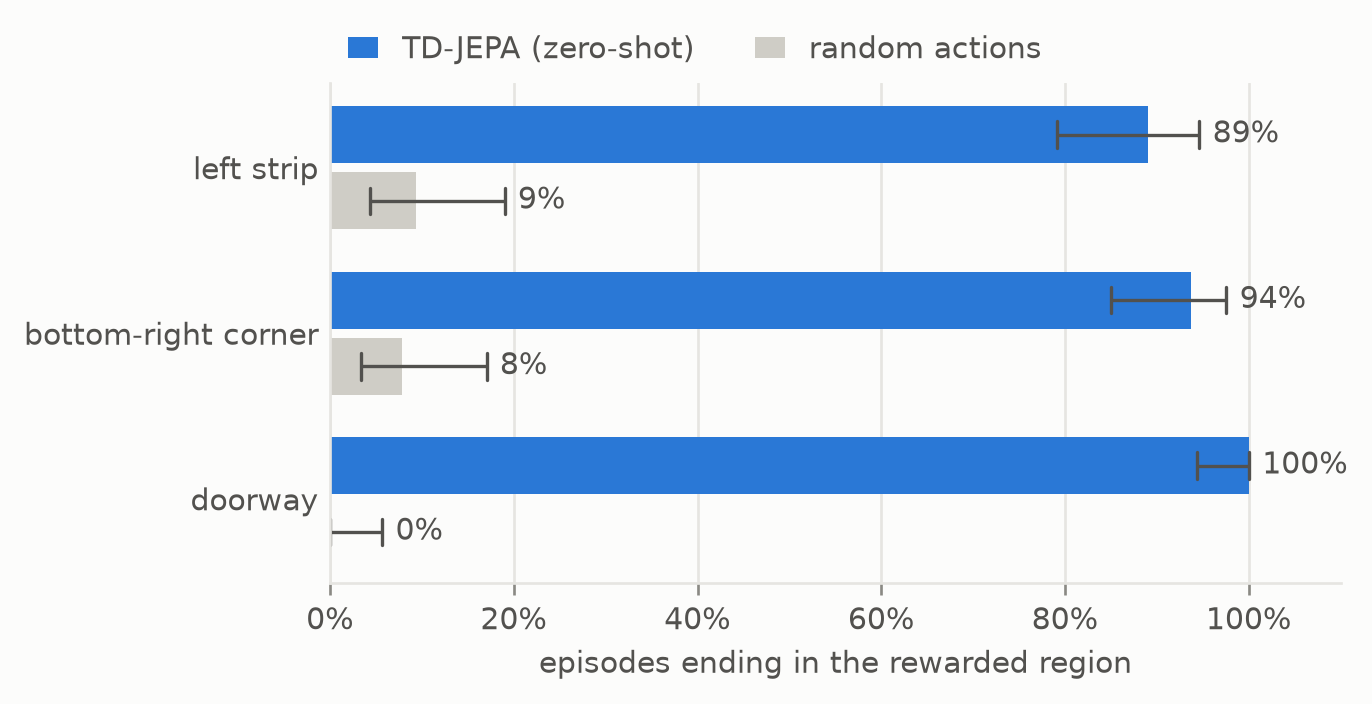

In [9]:
rewards = {
    "left strip": lambda s: s[..., 0] < 0.2,
    "bottom-right corner": lambda s: (s[..., 0] > 0.7) & (s[..., 1] > 0.7),
    "doorway": lambda s: ((s[..., 0] - 0.5).abs() < 0.1) & ((s[..., 1] - 0.5).abs() < 0.1),
}
idx = torch.randperm(data["states"][..., 0].numel(), generator=torch.Generator().manual_seed(2))[:2048]
frames, states = data["pixels"].flatten(0, 1)[idx], data["states"].flatten(0, 1)[idx]


def episodes(policy, steps=40):
    obs = env.reset(generator=torch.Generator().manual_seed(3))
    for _ in range(steps):
        obs = env.step(policy(obs))
    return env.state


transfer = {}
for name, reward in rewards.items():
    z = model.infer_task(frames, reward(states).float())
    transfer[name] = {
        "TD-JEPA (zero-shot)": metrics.success_rate(reward(episodes(model.controller(z)))),
        "random actions": metrics.success_rate(reward(episodes(evaluation.random_policy(env)))),
    }
    print(f"{name:20s}" + "  ".join(f"{k}: {v}" for k, v in transfer[name].items()))
plots.bars(transfer, xlabel="episodes ending in the rewarded region", baseline="random actions")

## Summary
From the pixels of random-action episodes and no rewards, TD-JEPA learns one set of policies that serves many tasks, each picked at test time without a gradient step. Goal images across the wall are reached 98% of the time [92%, 100%], against 31% for heading straight at the goal with the true positions and 3% for random actions. Goals in the same room are reached 100% of the time [94%, 100%], against 98% and 50%. Three rewards it never saw, inferred by one linear regression on 2,048 labeled frames, are solved in 89% to 100% of episodes, against 0% to 9% for random actions. The TD target is the discounted future task embedding, so the value of a goal image can propagate around the wall and through the door. A greedy controller cannot do this.

The policies reach goals but do not settle on them. The actor is greedy and keeps moving: its actions are jerky (smoothness 1.7, against 1.0 for random actions), its SPL is low (0.17), and success counts reaching the goal at any step. This run trains for 15k steps, against the paper's 1 to 2M. It also leaves out the behavior-cloning term the paper adds for OGBench's narrow datasets. The paper skips that term on high-coverage data like these too.